# Chapter 7: Dual-Function Beamforming for Integrated Sensing and Communication

Companion code for *Robust Adaptive Beamforming and Its Applications* by Ayman Elnashar (Wiley, forthcoming).

This notebook reproduces every simulation figure of Chapter 7 (Figures 7.1–7.9), Tables 7.1 and 7.3–7.6 and the numbers quoted in the text. One receive filter at a dual-function base station recovers uplink users, each on its own resource, and collects monostatic radar echoes; radar probing and uplink overlap in a fraction ρ = 0.3 of the resources. User SINR (7.5) and target SNR (7.6) are ratios of quadratic forms in the receive weight.

**RDF-AS-ISAC** (Algorithm 7.1) keeps every communication and sensing worst-case constraint and adapts only to identified interference:

* a forgetting covariance (7.13) is scanned every 10 observations with the Capon spectrum (7.14), evaluated exactly through the lag sums (7.15)–(7.16) of the planar array and refined to 0.25° and 0.05°;
* peaks are labelled as served users/targets or interference tracks, under a power ceiling 6 dB above the nominal user SNR; tracks are alpha-beta filtered (7.18) and predicted ahead by (7.19);
* the structured covariance (7.20) holds the predicted tracks and the noise floor, never the peaks labelled as served signals;
* the worst-case problem (7.11)–(7.12) is solved exactly in diagonal-loading form (7.23), each solve returns the duality-gap certificate (7.24), and the restoration (7.25) certifies every constraint.

The comparisons are base-radius and radius-matched SOCP (batch and re-solved online), projection reconstruction, the fixed beam, VU-MBWC, the true-covariance solution of the same problem and the single-function MVDR bounds (7.6b).

## Configuration

In [1]:
import os, sys, json
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1'); os.environ.setdefault('OMP_NUM_THREADS', '1')
sys.path.insert(0, os.path.abspath('..'))   # chapter folder, so that `ch7rdfisac` imports without installation
QUICK = False             # True: one or two seeds per point (smoke test, about 6 minutes)
REUSE_DATA = True         # True: reuse the stage data in FIGDIR/data when it is complete (e.g. written by scripts/generate_figures.py)
FIGDIR = os.path.abspath('../figures')
DATA = os.path.join(FIGDIR, 'data')
%matplotlib inline
from IPython.display import Image, Markdown, display
from ch7rdfisac import scenarios as S, summary, figures as F, verify
D = F.Data(DATA)

def fig(k):
    display(Image(filename=str(F.ALL[k](D, FIGDIR)), width=520))

def table(name):
    display(Markdown(open(os.path.join(FIGDIR, name + '.md'), encoding='utf-8').read()))

## Library

* `ch7rdfisac.algorithms`: RDF-AS-ISAC (Algorithm 7.1): lag-sum Capon scanner (`Scanner`), peak labelling with power ceiling, extended user claim and alpha-beta tracks (`Tracker`), exact loaded worst-case solution with certificate and restoration (`wc_loaded`), gain floors (7.22) and the full loop (`run_rdf_as_isac`).
* `ch7rdfisac.projection`: projection reconstruction (protected subspace, accelerated projected gradient with Dykstra cycles).
* `ch7rdfisac.baselines`: exact SOCP and SDP solutions of (7.11)–(7.12), VU-MBWC and the naive LCMV.
* `ch7rdfisac.simulator`, `scenes`, `rxmodel`: steering vectors (7.1), clustered uplink channel (7.2), snapshots (7.3), metrics (7.5)–(7.6), fixed Scenarios A–G and the random-geometry scene generator.
* `ch7rdfisac.scenarios`: the experiment stages of Section 7.7 with their seeds; `summary`: results_summary.json and the tables; `figures`: one function per figure; `verify`: comparison with the chapter.

## Settings (Section 7.7.1)

8 × 4 half-wavelength UPA; users at (20°, 5°) and (−30°, 8°), targets at (−5°, 0°) and (40°, −3°); user received SNR 8 dB, target amplitudes 0.8 and 0.7, N_f = 64; six clutter components of power 0.04; two 8 dB interferers at (62°, 2°) and (−65°, 1°); ρ = 0.3; two azimuth neighbours at ±2° per served direction (12 constraints). Scenarios F and G use three 25 dB interferers 6–12° from the served directions, drifting in G. RDF-AS-ISAC: η = 0.96 (1 − 1.28/M for other arrays), T_r = 10, radius 3ν₀, windows ±9° × ±4°, gates 2.5° × 1.5°, position gain 0.5, rate parameter 0.3, power tolerance ±6 dB, α = 0.5. Reference seeds 1–15, held-out seeds 5001–5015; settings were fixed on development seeds 2001–2012 and 8001–8008, which are not used here.

## Experiments

Each stage writes `FIGDIR/data/<stage>.json`. The full counts take about 30 minutes on two cores; the timing stage of Table 7.1 runs alone at the end.

In [2]:
def complete():
    return all(os.path.exists(os.path.join(DATA, s + '.json')) for s in S.STAGES)

if REUSE_DATA and complete() and not QUICK:
    print('reusing the stage data in', DATA)
else:
    S.run_stages(DATA, jobs=2, quick=QUICK)
N = summary.write(DATA, FIGDIR)
print('stages:', sorted(f[:-5] for f in os.listdir(DATA) if f.endswith('.json')))

reusing the stage data in ../figures/data


stages: ['alpha', 'array', 'cross', 'grid', 'load', 'main', 'sens', 'sweep', 'tightproj', 'timing']


## Table 7.1: Runtime versus array size

Single-thread times on the machine that runs this notebook (the chapter's values were measured on another machine). Scan and solve are standalone component benchmarks.

In [3]:
table('Table7_1_runtime')

| M | Array | RDF-AS-ISAC, 300 obs. (ms) | Scan per refresh (ms) | Solve per refresh (ms) | Update per obs. (µs) | Projection, 300 obs. (ms) | SOCP, one solve (ms) |
|---|---|---|---|---|---|---|---|
| 16 | 4 × 4 | 195 | 1.17 | 9.77 | 6 | 2620 | 14.2 |
| 32 | 8 × 4 | 152 | 1.81 | 9.61 | 9 | 9194 | 15.3 |
| 64 | 8 × 8 | 287 | 3.77 | 8.54 | 21 | 6476 | 31.2 |
| 128 | 16 × 8 | 544 | 9.76 | 13.04 | 76 | 8509 | 104.5 |
| 256 | 16 × 16 | 1510 | 25.98 | 28.68 | 333 | — | 381.8 |


## Table 7.3: Reference-scene means (dB)

In [4]:
table('Table7_3_reference_means')

| Scen. | Metric | RDF-AS-ISAC | Projection reconstr. | SOCP ν0 | SOCP 3ν0 | SOCP ν0, online | SOCP 3ν0, online | Fixed beam | True cov. | MVDR bound |
|---|---|---|---|---|---|---|---|---|---|---|
| A | γ_u1 (dB) | +10.87 | +10.49 | +9.88 | +10.48 | +7.78 | +9.25 | +10.36 | +11.21 | +20.11 |
|  | γ_u2 (dB) | +10.86 | +10.49 | +10.17 | +10.59 | +8.12 | +9.35 | +10.36 | +11.22 | +21.00 |
|  | γ_t1 (dB) | +10.33 | +10.12 | +10.39 | +10.29 | +10.11 | +10.08 | +10.10 | +10.17 | +29.00 |
|  | γ_t2 (dB) | +9.00 | +8.96 | +9.10 | +9.08 | +8.71 | +8.86 | +8.94 | +9.05 | +29.13 |
| B | γ_u1 (dB) | +9.75 | +9.16 | +0.77 | +6.67 | −1.08 | +5.81 | +9.03 | +9.98 | +20.18 |
|  | γ_u2 (dB) | +9.61 | +9.25 | +1.86 | +6.88 | +0.30 | +5.77 | +9.13 | +10.28 | +21.04 |
|  | γ_t1 (dB) | +11.16 | +11.03 | +13.29 | +12.39 | +12.80 | +12.13 | +11.01 | +10.97 | +29.11 |
|  | γ_t2 (dB) | +9.83 | +9.87 | +12.11 | +11.17 | +11.60 | +10.92 | +9.85 | +9.85 | +29.10 |
| C | γ_u1 (dB) | +11.37 | +10.88 | +10.30 | +10.93 | +8.10 | +9.61 | +10.74 | +11.73 | +20.19 |
|  | γ_u2 (dB) | +11.33 | +10.88 | +10.60 | +11.04 | +8.43 | +9.71 | +10.74 | +11.74 | +21.18 |
|  | γ_t1 (dB) | +9.48 | +9.37 | +9.25 | +9.39 | +8.93 | +9.16 | +9.35 | +9.20 | +28.82 |
|  | γ_t2 (dB) | +7.90 | +8.21 | +8.39 | +8.21 | +8.07 | +8.03 | +8.19 | +8.36 | +28.84 |
| D | γ_u1 (dB) | +10.36 | +9.84 | +3.52 | +7.95 | +1.47 | +7.01 | +9.70 | +10.72 | +20.24 |
|  | γ_u2 (dB) | +10.29 | +9.95 | +3.51 | +8.03 | +1.72 | +6.87 | +9.81 | +10.98 | +21.17 |
|  | γ_t1 (dB) | +10.45 | +10.28 | +11.46 | +11.34 | +11.13 | +11.09 | +10.26 | +10.08 | +28.91 |
|  | γ_t2 (dB) | +8.87 | +9.11 | +10.00 | +9.86 | +9.95 | +9.69 | +9.08 | +9.15 | +28.94 |
| F | γ_u1 (dB) | +9.37 | −17.24 | +3.85 | +3.44 | +2.24 | +2.77 | −17.01 | +9.85 | +19.88 |
|  | γ_u2 (dB) | +9.04 | −16.28 | +4.43 | +3.61 | +3.09 | +2.95 | −16.89 | +9.46 | +20.06 |
|  | γ_t1 (dB) | +9.42 | −9.36 | +10.61 | +8.80 | +10.11 | +8.45 | −8.49 | +9.49 | +27.47 |
|  | γ_t2 (dB) | +7.26 | −9.61 | +8.86 | +6.73 | +8.31 | +6.37 | −9.67 | +7.37 | +19.15 |
| G | γ_u1 (dB) | +7.19 | −18.59 | −3.87 | −9.45 | −4.80 | −4.34 | −18.59 | +10.52 | +18.95 |
|  | γ_u2 (dB) | +6.08 | −17.63 | −3.40 | −9.02 | −3.63 | −4.07 | −18.47 | +9.38 | +21.15 |
|  | γ_t1 (dB) | +7.65 | −10.68 | +5.17 | −1.87 | +5.44 | +2.78 | −10.06 | +8.38 | +25.34 |
|  | γ_t2 (dB) | +5.53 | −10.94 | +2.12 | −3.16 | +3.16 | +1.14 | −11.24 | +6.31 | +18.03 |


## Table 7.4: Held-out paired gains of RDF-AS-ISAC (dB, mean and 95% interval)

In [5]:
table('Table7_4_heldout_paired')

| Scen. | Metric | vs Projection reconstr. | vs SOCP 3ν0, batch | vs SOCP 3ν0, online | vs True covariance |
|---|---|---|---|---|---|
| A | Users | +0.35 [0.27, 0.42] | +0.36 [0.16, 0.56] | +1.29 [0.84, 1.73] | −0.35 [−0.45, −0.26] |
|  | Targets | +0.13 [0.06, 0.20] | −0.01 [−0.13, 0.12] | +0.13 [−0.04, 0.31] | +0.03 [−0.05, 0.11] |
| B | Users | +0.50 [−0.01, 1.01] | +3.68 [1.55, 5.80] | +4.49 [2.63, 6.35] | −0.18 [−0.82, 0.45] |
|  | Targets | +0.05 [−0.29, 0.39] | −1.56 [−2.52, −0.60] | −1.27 [−2.25, −0.28] | −0.03 [−0.43, 0.37] |
| C | Users | +0.43 [0.32, 0.54] | +0.41 [0.18, 0.64] | +1.41 [0.91, 1.92] | −0.37 [−0.50, −0.23] |
|  | Targets | +0.06 [−0.16, 0.29] | +0.08 [−0.23, 0.38] | +0.18 [−0.14, 0.50] | +0.01 [−0.26, 0.28] |
| D | Users | +0.47 [0.06, 0.88] | +2.69 [1.20, 4.19] | +3.72 [2.36, 5.08] | −0.29 [−0.80, 0.23] |
|  | Targets | +0.07 [−0.27, 0.41] | −1.07 [−1.94, −0.20] | −0.84 [−1.72, 0.05] | +0.01 [−0.37, 0.39] |
| F | Users | +25.68 [25.00, 26.36] | +6.19 [5.54, 6.85] | +6.79 [6.26, 7.31] | −0.50 [−0.63, −0.37] |
|  | Targets | +17.91 [16.92, 18.90] | +0.49 [−0.09, 1.07] | +0.84 [0.27, 1.40] | −0.10 [−0.21, 0.01] |
| G | Users | +23.86 [23.12, 24.60] | +15.39 [14.95, 15.83] | +10.40 [9.76, 11.04] | −3.51 [−3.76, −3.26] |
|  | Targets | +17.49 [15.93, 19.04] | +9.12 [8.32, 9.93] | +4.50 [3.92, 5.08] | −0.88 [−0.97, −0.79] |


## Figure 7.1: Held-out paired gains

Paired gains of RDF-AS-ISAC in mean user SINR and mean target SNR on the 15 held-out scenes per scenario, with 95% Student-t intervals (Table 7.4). The vertical axis is linear within ±1 dB and logarithmic beyond.

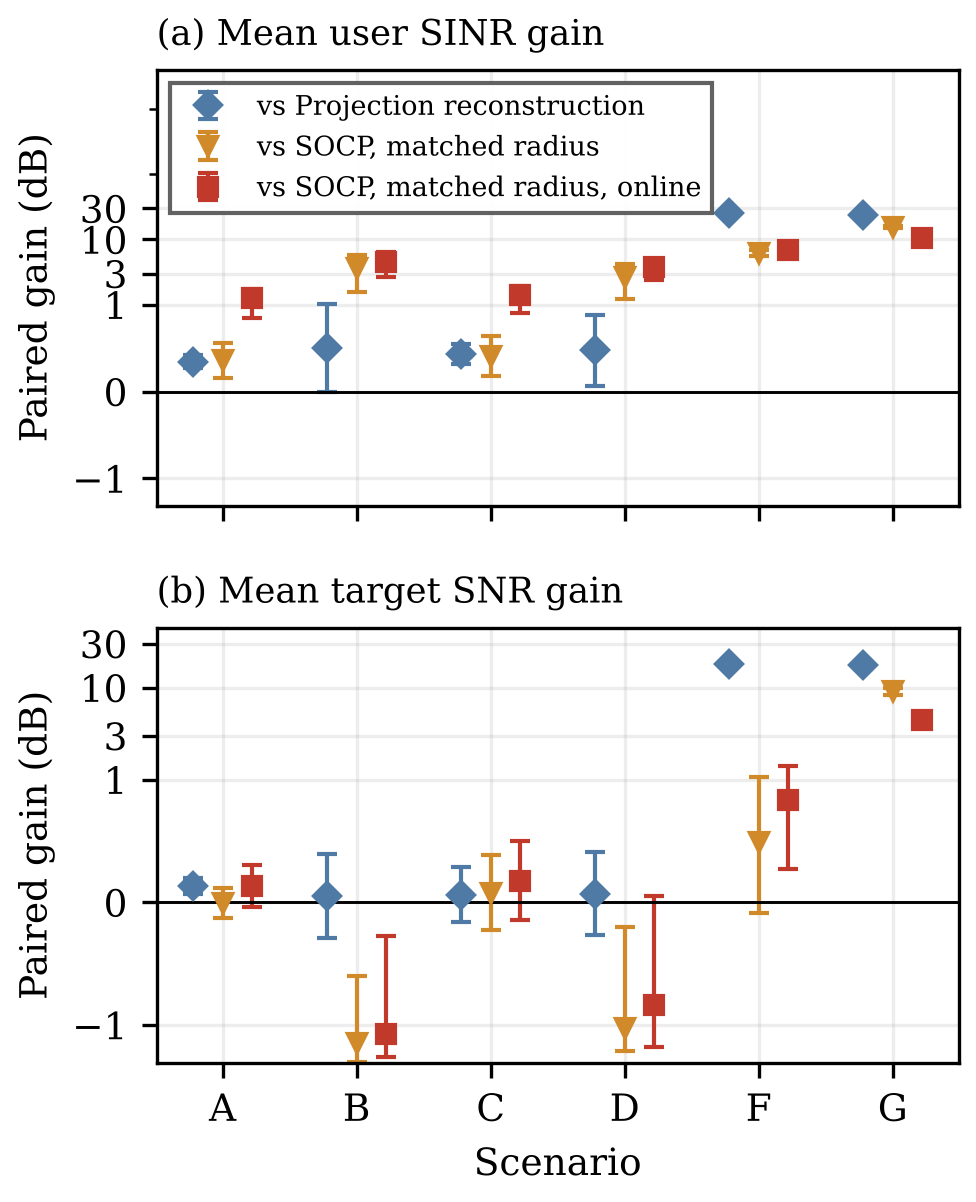

In [6]:
fig(1)

## Text of Section 7.7.2 and 7.7.3

Exact conic solve on the projection-reconstruction covariance, users below 0 dB in Scenarios A–D, SDP/SOCP agreement.

In [7]:
print('held-out user gain over projection reconstruction (iterative / exact conic solve):', N['exact_projection_gain'])
print('users below 0 dB, A-D scenes:', N['users_below_0dB_AD'], 'of', N['n_AD'])
print('largest SDP-SOCP difference (dB): %.4f' % N['sdp_socp_maxdiff'])

held-out user gain over projection reconstruction (iterative / exact conic solve): {'F': {'iterative': 25.68, 'exact': 25.92}, 'G': {'iterative': 23.86, 'exact': 24.33}}
users below 0 dB, A-D scenes: {'bound': 0, 'fixed': 0, 'naive': 114, 'projection': 0, 'rdf_as_isac': 0, 'sdp': 29, 'socp': 29, 'socp_online': 31, 'socp_radius': 10, 'socp_radius_online': 12, 'true_cov': 0, 'vu_mbwc': 44} of 120
largest SDP-SOCP difference (dB): 0.0052


## Table 7.5: Random geometry, array size and load (mean user SINR / mean target SNR, dB)

In [8]:
table('Table7_5_random_geometry')

| Case | Interference | RDF-AS-ISAC | Projection reconstr. | SOCP ν0 | SOCP 3ν0 | Fixed beam | True cov. | MVDR bound |
|---|---|---|---|---|---|---|---|---|
| M = 16 | benign | 7.7 / 8.6 | 3.7 / 7.2 | 5.6 / 9.5 | 5.1 / 8.4 | 3.6 / 7.1 | 9.4 / 9.1 | 16.1 / 22.8 |
| M = 16 | strong | −19.2 / −11.0 | −20.9 / −13.3 | −7.2 / 2.0 | −19.2 / −11.1 | −20.9 / −13.3 | −19.2 / −11.1 | 5.7 / 16.0 |
| M = 32 | benign | 11.0 / 8.7 | 8.1 / 8.5 | 4.5 / 9.9 | 8.6 / 9.8 | 8.1 / 8.5 | 10.9 / 9.0 | 21.4 / 28.4 |
| M = 32 | strong | 2.9 / 7.0 | −15.4 / −8.0 | 3.4 / 10.3 | −0.5 / 5.7 | −15.4 / −8.0 | 4.1 / 7.1 | 17.3 / 25.4 |
| M = 64 | benign | 11.9 / 8.7 | 9.4 / 8.4 | −1.4 / 11.0 | 9.2 / 10.2 | 9.3 / 8.4 | 12.1 / 8.8 | 24.9 / 31.7 |
| M = 64 | strong | 9.1 / 9.4 | −15.9 / −8.5 | 0.4 / 11.5 | 3.9 / 8.8 | −16.0 / −8.7 | 9.8 / 10.0 | 21.4 / 29.4 |
| M = 128 | benign | 11.8 / 9.1 | 10.0 / 8.7 | −6.7 / 7.9 | 6.8 / 11.2 | 9.9 / 8.7 | 12.0 / 8.5 | 28.3 / 35.4 |
| M = 128 | strong | 11.6 / 8.7 | −7.8 / −0.7 | −7.8 / 11.4 | 7.8 / 10.7 | −8.3 / −1.2 | 11.7 / 9.4 | 27.6 / 34.8 |
| U = T = 2 | benign | 11.3 / 8.7 | 8.9 / 9.2 | −2.1 / 12.4 | 8.6 / 10.7 | 8.8 / 9.2 | 11.3 / 9.6 | 24.1 / 31.6 |
| U = T = 2 | strong | 2.9 / 8.4 | −17.1 / −9.0 | −3.5 / 12.1 | −0.3 / 8.2 | −17.3 / −9.2 | 6.4 / 9.7 | 19.4 / 29.9 |
| U = T = 3 | benign | 9.1 / 8.2 | 8.7 / 8.1 | 1.5 / 11.1 | 7.9 / 9.1 | 8.6 / 8.2 | 9.3 / 8.2 | 23.9 / 31.8 |
| U = T = 3 | strong | 3.5 / 4.1 | −17.9 / −9.8 | 2.6 / 9.5 | −2.5 / 2.4 | −17.8 / −10.0 | 3.8 / 4.0 | 22.1 / 28.9 |
| U = T = 4 | benign | 8.2 / 6.3 | 7.5 / 6.0 | 1.7 / 8.8 | 6.7 / 6.6 | 7.3 / 6.0 | 8.5 / 6.1 | 23.7 / 30.9 |
| U = T = 4 | strong | −4.9 / −1.0 | −17.9 / −11.1 | 0.8 / 7.1 | −7.4 / −2.3 | −17.9 / −11.2 | −0.5 / 0.9 | 20.6 / 28.5 |


## Figure 7.2: Interference separation, power and mismatch

User SINR versus (a) the azimuth offset of a 25 dB interferer from user 1, (b) its INR at 8° offset and (c) the joint angular error in Scenario D. Eight scenes per point (seeds 6101–6108), M = 32.

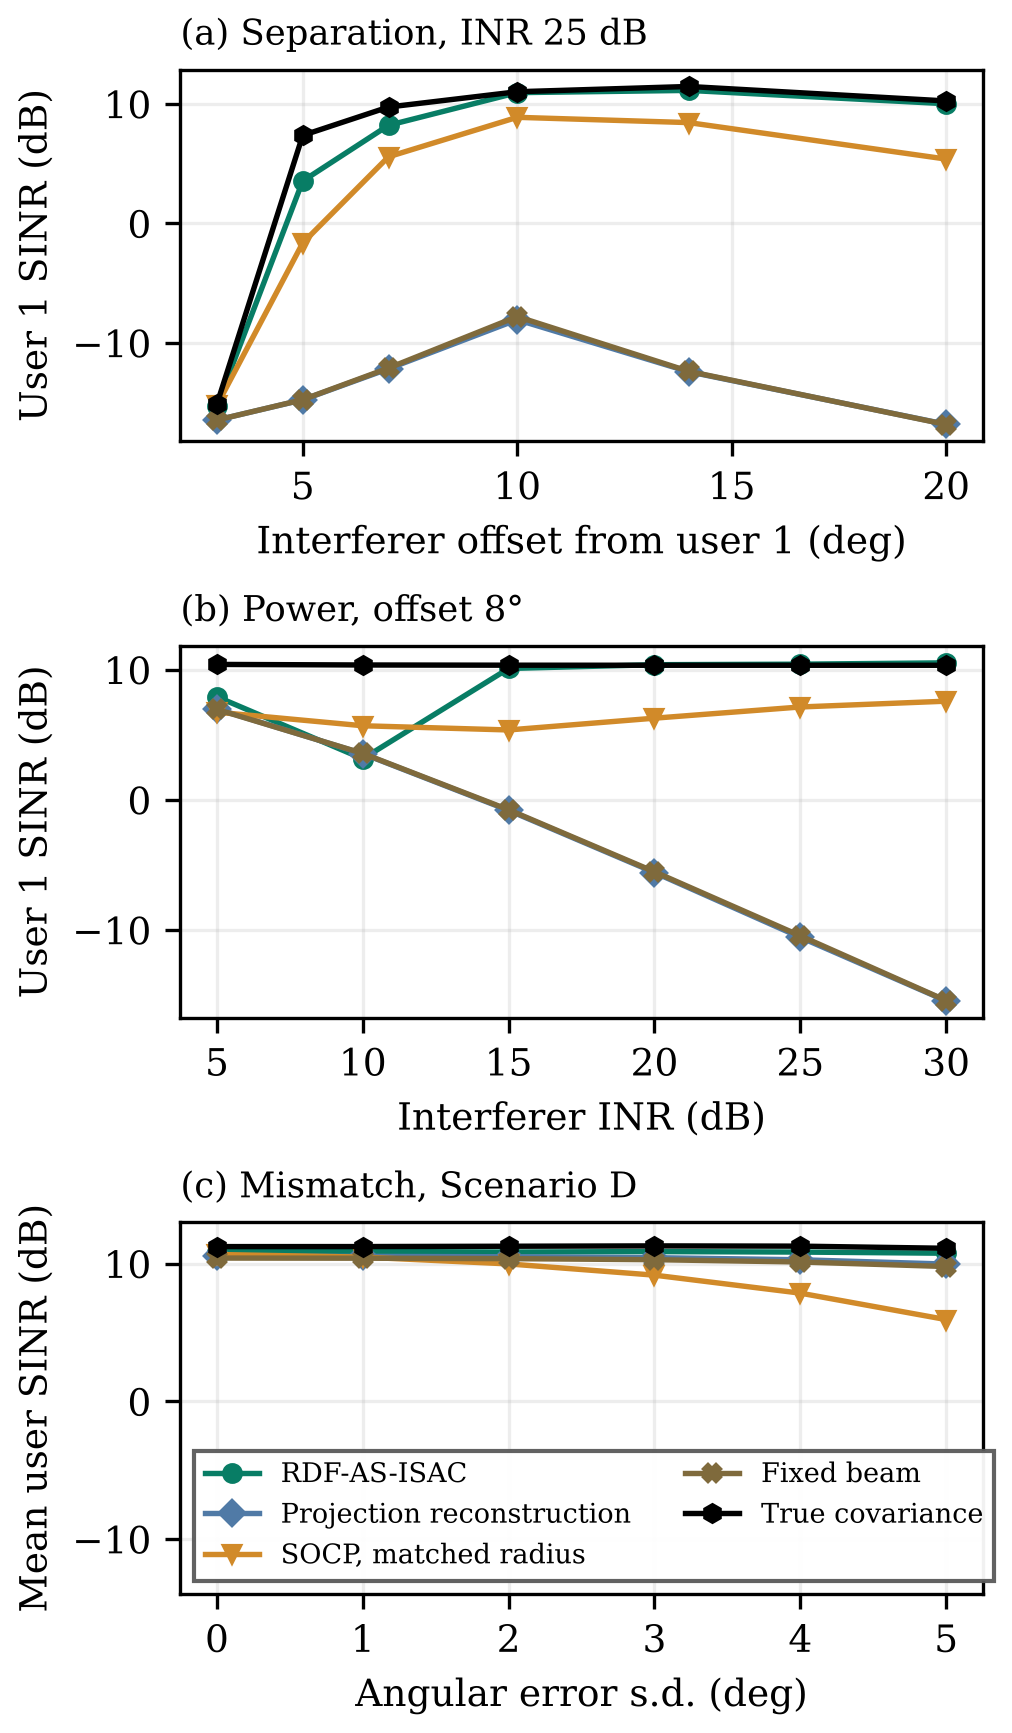

In [9]:
fig(2)

## Figure 7.3: Target crossing a user

Target 1 moves from 15° to 0° in azimuth from user 1; error standard deviations 2°, seeds 6401–6408.

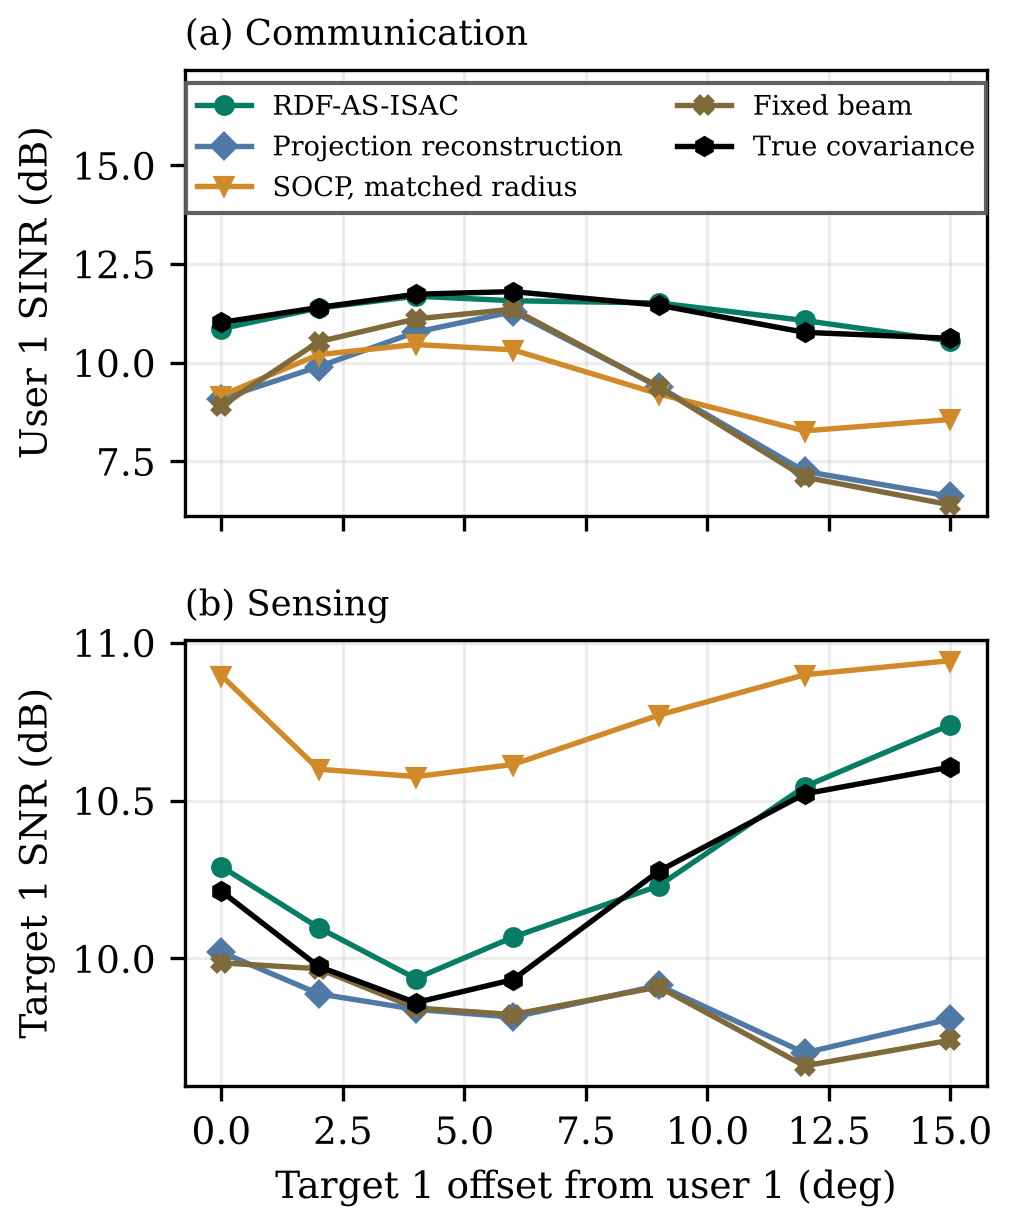

In [10]:
fig(3)

## Table 7.6: One-at-a-time parameter sensitivity (mean user SINR / mean target SNR, dB)

In [11]:
table('Table7_6_sensitivity')

| Setting | Scenario D | Scenario F | Scenario G |
|---|---|---|---|
| Default | 10.80 / 9.47 | 9.09 / 7.83 | 5.75 / 6.35 |
| Window ±6° | 10.80 / 9.47 | 9.09 / 7.83 | 5.75 / 6.35 |
| Window ±12° | 10.80 / 9.47 | 9.10 / 7.83 | 5.75 / 6.35 |
| η = 0.94 | 10.80 / 9.48 | 9.08 / 7.83 | 5.69 / 6.35 |
| η = 0.98 | 10.82 / 9.45 | 9.03 / 7.81 | 5.30 / 5.81 |
| T_r = 5 | 10.79 / 9.46 | 8.98 / 7.82 | 5.86 / 6.30 |
| T_r = 20 | 10.81 / 9.47 | 9.25 / 7.86 | 2.79 / 5.08 |
| Tolerance ±3 dB | 10.80 / 9.47 | 9.09 / 7.83 | 5.69 / 6.36 |
| Tolerance ±10 dB | 10.80 / 9.47 | 9.09 / 7.83 | 5.84 / 6.35 |
| Rate gain 0.1 | 10.81 / 9.47 | 9.22 / 7.86 | 2.70 / 5.18 |
| Rate gain 0.5 | 10.79 / 9.46 | 8.98 / 7.81 | 6.01 / 6.39 |
| Position gain 0.3 | 10.81 / 9.47 | 9.10 / 7.83 | 5.44 / 6.24 |
| Position gain 1 | 10.80 / 9.47 | 8.98 / 7.81 | 5.65 / 6.30 |
| Radius 2ν0 | 10.81 / 9.36 | 9.12 / 7.69 | 5.37 / 6.56 |
| Radius 4ν0 | 10.82 / 9.54 | 8.29 / 7.65 | 0.25 / 2.54 |


## Figure 7.4: Adaptation

Causal user 1 SINR in Scenarios D, F and G, 15 reference scenes. The true-covariance solution is evaluated every 25 observations.

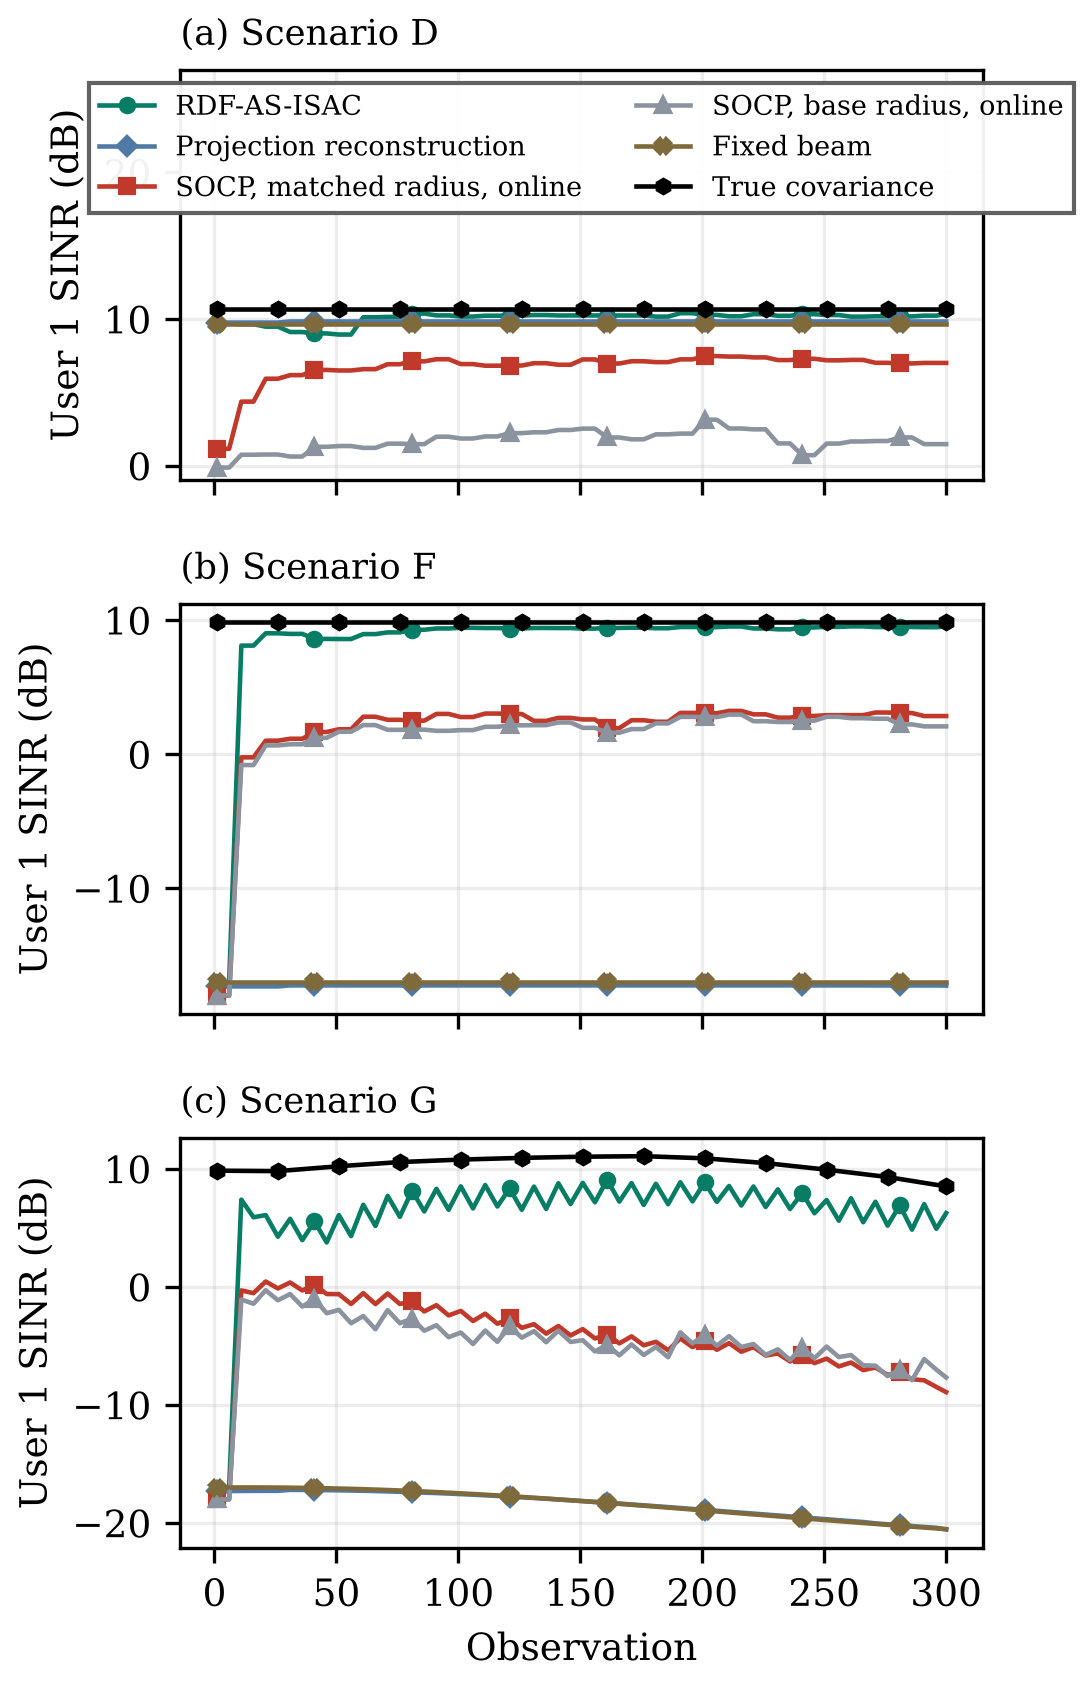

In [12]:
fig(4)

## Figure 7.5: Beam patterns

Mean normalized array response at elevation 2° in Scenarios D and F (batch radius-matched SOCP in D, online in F).

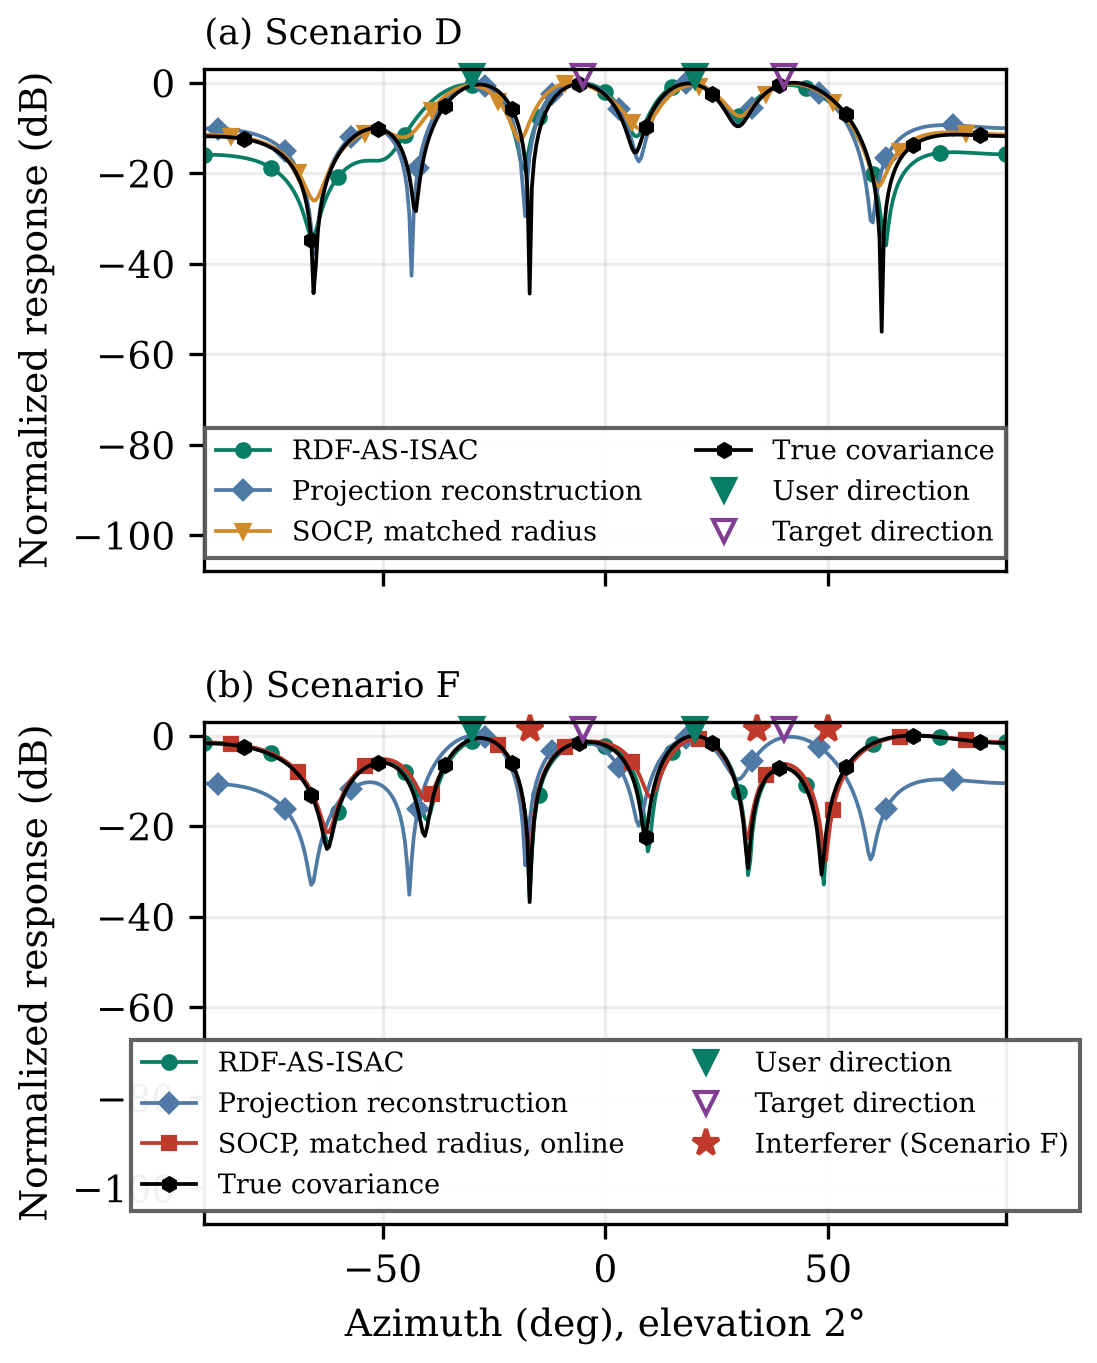

In [13]:
fig(5)

## Figure 7.6: Constraint satisfaction and certificate

Largest certified duality gap (7.24) over all refreshes of each scene and absolute final-refresh gap (7.28) to a tight conic solve, all 180 scenes.

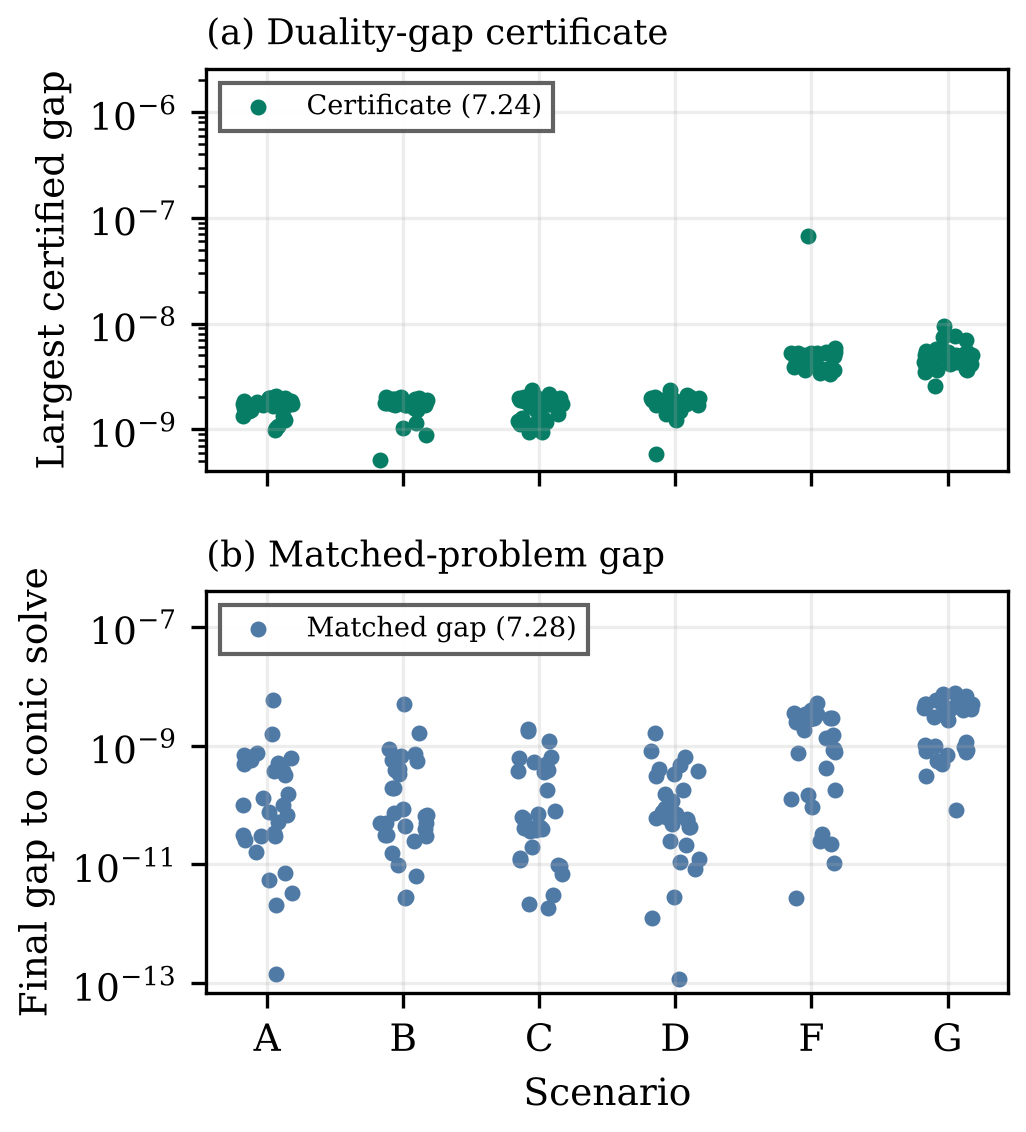

In [14]:
fig(6)

In [15]:
print(json.dumps(N['checks'], indent=1))

{
 "min_margin": 9.965361869035405e-13,
 "max_cert": 6.680653430337507e-08,
 "max_gap": 7.569368243309782e-09,
 "max_gap_AD": 1.8731411977057633e-09,
 "median_iter": 61,
 "frac_iter_cap": 0.00037037037037037035,
 "n_scenes": 180,
 "n_weights": 54000
}


## Figure 7.7: Communication and sensing priority

Mean user SINR and target SNR versus α in Scenario D, seeds 7001–7010.

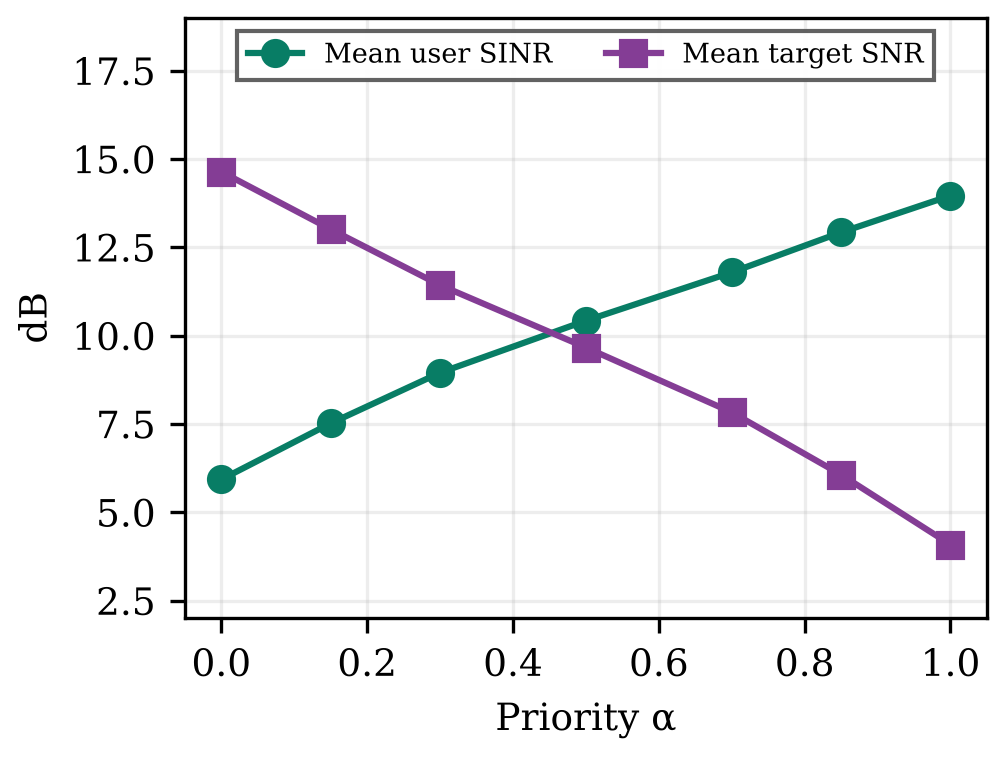

In [16]:
fig(7)

## Figure 7.8: Scenario E coverage

Service-threshold coverage on the 7 × 7 grid of angular-error standard deviations; three scenes per cell (seeds 6001–6003), 150 observations.

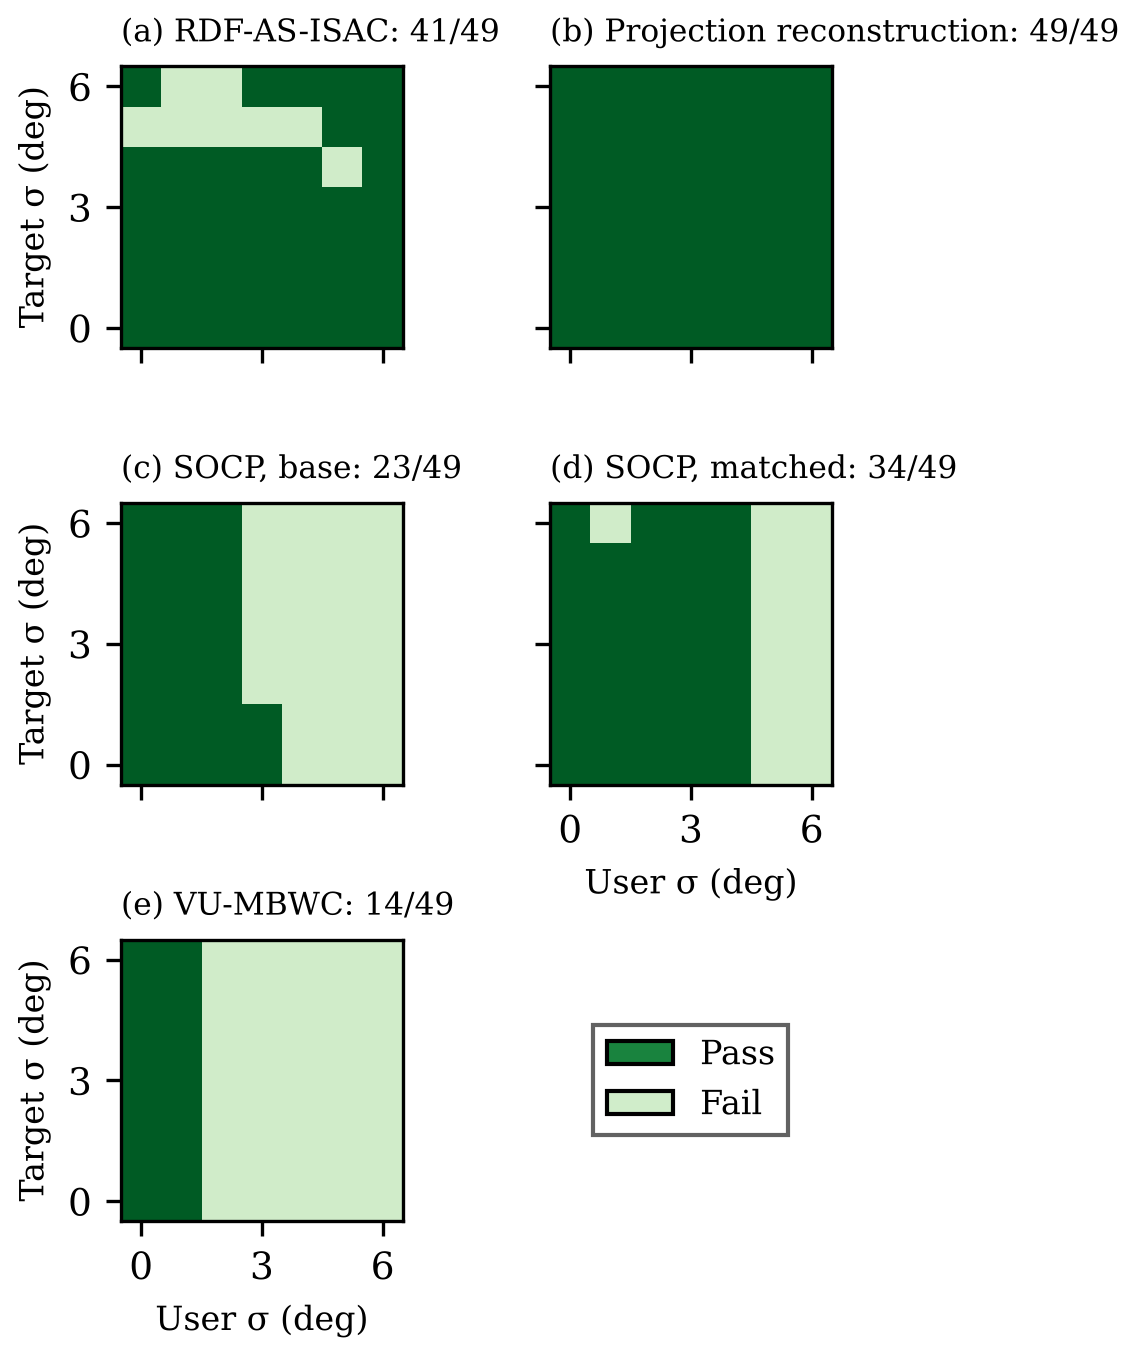

In [17]:
fig(8)

## Figure 7.9: Detection with fluctuating targets

Mean worst-target detection probability versus false-alarm probability in Scenario D (30 scenes), Swerling 1 targets, one coherent look.

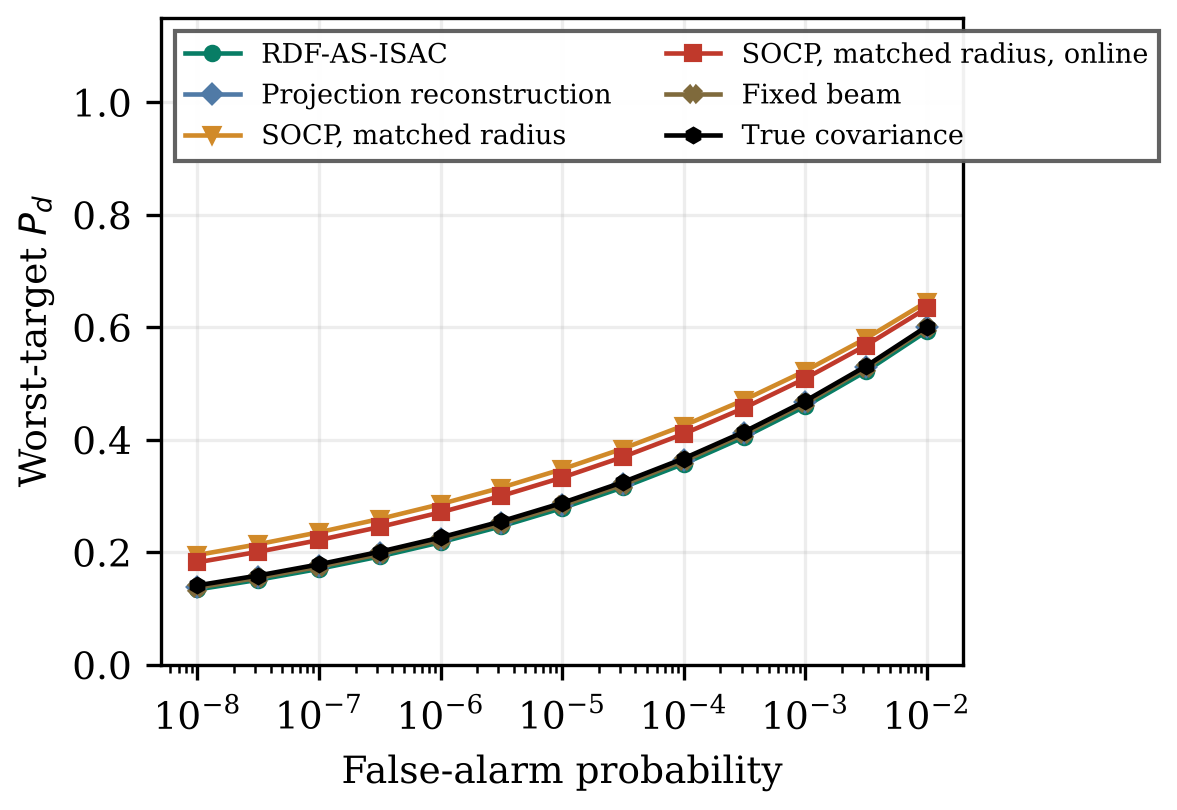

In [18]:
fig(9)

In [19]:
print('coverage (of 49):', N['coverage'])
print('worst-target Pd at Pfa = 1e-4 (Swerling 0, 1, 3):', {a: [v[s]['worst'] for s in ('sw0', 'sw1', 'sw3')] for a, v in N['detection_by_pfa']['1e-04'].items()})

coverage (of 49): {'rdf_as_isac': 41, 'projection': 49, 'socp': 23, 'socp_radius': 34, 'vu_mbwc': 14}
worst-target Pd at Pfa = 1e-4 (Swerling 0, 1, 3): {'rdf_as_isac': [0.44, 0.36, 0.39], 'projection': [0.46, 0.36, 0.4], 'socp': [0.58, 0.42, 0.48], 'socp_radius': [0.59, 0.42, 0.48], 'socp_radius_online': [0.55, 0.41, 0.46], 'fixed': [0.45, 0.36, 0.4], 'vu_mbwc': [0.48, 0.35, 0.39], 'true_cov': [0.46, 0.37, 0.4]}


## Comparison with the chapter

Every value of Tables 7.3–7.6 and the numbers quoted in Sections 7.7.2–7.7.12 (timings excluded).

In [20]:
verify.main([FIGDIR])

492 of 492 chapter values reproduced


0